# Lab 9. Plotting and Visualization

In [2]:
student_name = "Daniyaruly Kaiyrzhan"   # e.g. "Arman Omar"


## Rules

1. Go **top to bottom**. Write your code where you see `# YOUR CODE HERE` or `None`.
2. Do not edit the *given data* cells or the *check* cells.
3. Use the **object-oriented style**: call methods on the `fig` and `ax` objects (`ax.plot(...)`, `ax.set_title(...)`),
   not `plt.title(...)`. In Jupyter a figure is closed after its cell runs, so `plt.xxx` would hit a new empty figure.
4. Every task ends with a **check cell** that prints `PASS` or `FAIL`. It never stops the notebook. The check looks at the
   figure objects (title, labels, number of lines or bars, legend and so on), so it can only judge what is really on the figure.
5. The last cell shows your automatic score.
6. Before you submit: **Kernel > Restart & Run All**, make sure nothing raises an error, save, upload the `.ipynb`.
7. **Defense:** at the end there are questions you will answer aloud. Be ready to change your plot live.

## Setup
Run this cell first. It imports the libraries and defines the self-check helper.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.text import Annotation

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 120)
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    SEABORN = sns.__version__
except ImportError:
    SEABORN = None
    print("seaborn is NOT installed: run  pip install seaborn  and restart the kernel (needed for Part 4).")
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", SEABORN)

# ----- Self-check helper. Do not edit this cell. -----
POINTS = {"1.1": 4, "1.2": 5, "1.3": 5, "1.4": 4, "1.5": 4, "2.1": 5, "2.2": 5, "2.3": 5, "2.4": 5, "3.1": 3, "3.2": 4, "3.3": 3, "3.4": 5, "3.5": 5, "3.6": 4, "4.1": 4, "4.2": 4, "4.3": 3, "4.4": 4, "5.1": 3, "5.2": 4, "5.3": 3, "5.4": 3, "5.5": 3, "5.6": 3}
_results = {}


def check(task_id, condition):
    """Run `condition` (a lambda returning True/False), print PASS or FAIL and remember the result."""
    try:
        ok = bool(condition())
        print(f"Task {task_id}: {'PASS' if ok else 'FAIL'}")
    except Exception as exc:
        ok = False
        print(f"Task {task_id}: FAIL ({type(exc).__name__}: {exc})")
    _results[task_id] = ok


def summary():
    """Print the automatic score per task and per part."""
    rows, by_part, part_max = [], {}, {}
    for tid, pts in POINTS.items():
        got = pts if _results.get(tid) else 0
        part = tid.split(".")[0]
        by_part[part] = by_part.get(part, 0) + got
        part_max[part] = part_max.get(part, 0) + pts
        rows.append((tid, pts, got, "PASS" if _results.get(tid) else ("FAIL" if tid in _results else "not run")))
    display(pd.DataFrame(rows, columns=["task", "max", "earned", "result"]).set_index("task"))
    print()
    for part in sorted(part_max, key=int):
        print(f"Part {part}: {by_part[part]:>3} / {part_max[part]}")
    print(f"TOTAL (automatic): {sum(by_part.values())} / {sum(part_max.values())}")

pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2


## Given data

| Name | What it is |
|---|---|
| `tips` | 120 restaurant bills: `total_bill`, `tip`, `smoker`, `day`, `time`, `size`, `tip_pct` |
| `monthly` | revenue of three regions by month (million KZT) |
| `kz` | 21 regions and cities of Kazakhstan: `region`, `kind` (`region` or `city`), `area_km2`, `pop_2009`, `pop_2022` (used in Part 5) |
| `walk`, `noise`, `xs`, `ys` | small arrays for Part 1 |

The data is generated with a fixed seed, so everybody has the same numbers.
**Trap:** one row of `tips` has a data entry error (a 240 percent tip). You will meet it in Part 3.

In [4]:
rng = np.random.default_rng(42)

# ---- restaurant bills (like the tips dataset of the lecture) ----
n = 120
day = rng.choice(["Thur", "Fri", "Sat", "Sun"], size=n, p=[0.2, 0.1, 0.35, 0.35])
time = np.where(np.isin(day, ["Sat", "Sun"]), "Dinner", rng.choice(["Lunch", "Dinner"], size=n, p=[0.7, 0.3]))
total_bill = np.round(rng.lognormal(mean=2.9, sigma=0.4, size=n), 2)
tip_pct = np.clip(rng.normal(0.16, 0.04, size=n), 0.05, None)
tips = pd.DataFrame({
    "total_bill": total_bill,
    "tip": np.round(total_bill * tip_pct, 2),
    "smoker": rng.choice(["No", "Yes"], size=n, p=[0.6, 0.4]),
    "day": day,
    "time": time,
    "size": rng.integers(1, 7, size=n),
})
tips.loc[7, "tip"] = round(tips.loc[7, "total_bill"] * 2.4, 2)     # a data entry error: a 240 percent tip
tips["tip_pct"] = tips["tip"] / tips["total_bill"]

# ---- monthly revenue by region, million KZT ----
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = pd.DataFrame(
    np.round(50 + rng.normal(2, 4, size=(12, 3)).cumsum(axis=0), 1),
    columns=["North", "South", "East"], index=months,
)

# ---- small arrays for Part 1 ----
walk = rng.standard_normal(30).cumsum()          # a random walk
noise = rng.normal(15, 5, size=100)              # values mostly between 0 and 30
xs = np.arange(30)
ys = xs + 3 * rng.standard_normal(30)

# ---- regions of Kazakhstan (Wikipedia table: area km2, population 2009 and 2022) ----
kz = pd.DataFrame(
    [("Abai", "region", 185500, 654423, 610183), ("Aqmola", "region", 146219, 737495, 786012),
     ("Aqtobe", "region", 300629, 757768, 924845), ("Almaty", "city", 682, 1449696, 2147113),
     ("Almaty Region", "region", 105100, 1103237, 1497025), ("Astana", "city", 797, 613006, 1340782),
     ("Atyrau", "region", 118631, 510377, 689674), ("Baikonur", "city", 57, 36175, 34544),
     ("East Kazakhstan", "region", 97700, 742170, 730818), ("Jambyl", "region", 144264, 1022129, 1215482),
     ("Jetisu", "region", 118500, 620593, 698952), ("Karaganda", "region", 239100, 1118036, 1134146),
     ("Kostanay", "region", 196001, 885570, 832445), ("Kyzylorda", "region", 226019, 678794, 830901),
     ("Mangystau", "region", 165642, 485392, 761401), ("North Kazakhstan", "region", 97993, 596535, 534966),
     ("Pavlodar", "region", 124800, 742475, 754829), ("Shymkent", "city", 1163, 730873, 1184113),
     ("Turkistan", "region", 116100, 1738484, 2110502), ("West Kazakhstan", "region", 151339, 598880, 686655),
     ("Ulytau", "region", 188900, 223664, 221014)],
    columns=["region", "kind", "area_km2", "pop_2009", "pop_2022"],
)

print(tips.shape, monthly.shape, kz.shape)
tips.head()

(120, 7) (12, 3) (21, 5)


,total_bill,tip,smoker,day,time,size,tip_pct
0,13.58,2.75,No,Sun,Dinner,1,0.202504
1,13.99,2.37,Yes,Sat,Dinner,6,0.169407
2,7.70,1.30,No,Sun,Dinner,1,0.168831
3,17.03,2.91,No,Sun,Dinner,2,0.170875
4,11.88,1.49,Yes,Thur,Lunch,5,0.125421


---
# Part 1. Figures, subplots, line styles, legends (22 points)

| Goal | Code |
|---|---|
| figure with a grid of axes | `fig, axes = plt.subplots(2, 2, sharex=True, figsize=(8, 6))` |
| draw on one axes | `axes[0, 0].plot(...)`, `.hist(...)`, `.scatter(...)` |
| format string | `"ko--"` = black (`k`), circle markers (`o`), dashed line (`--`) |
| legend | give `label="..."` to every line, then `ax.legend(loc="best")` |
| spacing | `fig.subplots_adjust(wspace=..., hspace=...)` |

In this part you fill **one figure with four panels** step by step.

### Theory: Figure, Axes and the two styles

* A **Figure** is the whole canvas. An **Axes** is one plot area inside it (with its own x axis, y axis, title, legend).
* **pyplot style:** `plt.plot(...)`, `plt.title(...)` act on the "current" axes (hidden global state). Quick, but in Jupyter the figure
  is closed after the cell runs, so a later `plt.title(...)` hits a **new empty figure**.
* **Object-oriented style (use this in the lab):** `fig, ax = plt.subplots()` and then `ax.plot(...)`, `ax.set_title(...)`.
  With several panels `plt.subplots(2, 2)` returns `axes` as a 2D array: `axes[0, 1]` is row 0, column 1.
* A **format string** `"g--o"` = colour `g` (green) + line style `--` (dashed) + marker `o` (circles).
  Colours: `b g r c m y k w`. Markers: `o * s ^ . +`. Styles: `-  --  :  -.`.
* `hist(data, bins=...)` counts values in bins, `scatter(x, y)` draws points, `legend()` shows the `label=` of every line.

### Example (run it and change something)

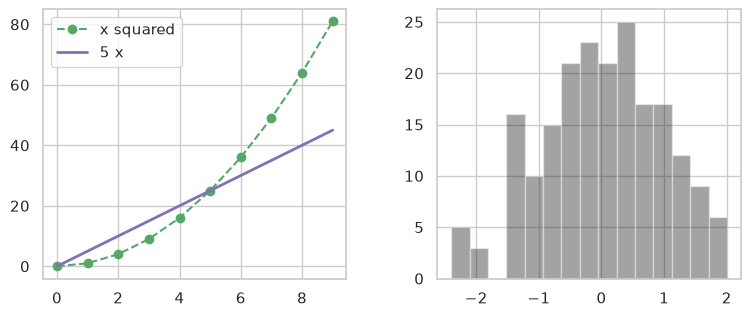

In [5]:
ex_x = np.arange(10)
ex_fig, ex_axes = plt.subplots(1, 2, figsize=(9, 3.5))            # 1 row, 2 columns -> axes is a 1D array
ex_axes[0].plot(ex_x, ex_x ** 2, "g--o", label="x squared")         # format string
ex_axes[0].plot(ex_x, 5 * ex_x, "m-", linewidth=2, label="5 x")     # keyword arguments
ex_axes[0].legend(loc="upper left")
ex_axes[1].hist(np.random.default_rng(0).normal(size=200), bins=15, color="k", alpha=0.4)
ex_fig.subplots_adjust(wspace=0.3)                                  # gap between the panels

### Task 1.1 (4 pts): Create the figure

Create `fig` and `axes`: a figure with **2 rows and 2 columns** of axes, size **8 by 6 inches**,
where **all axes share the same x axis** (`sharex=True`).

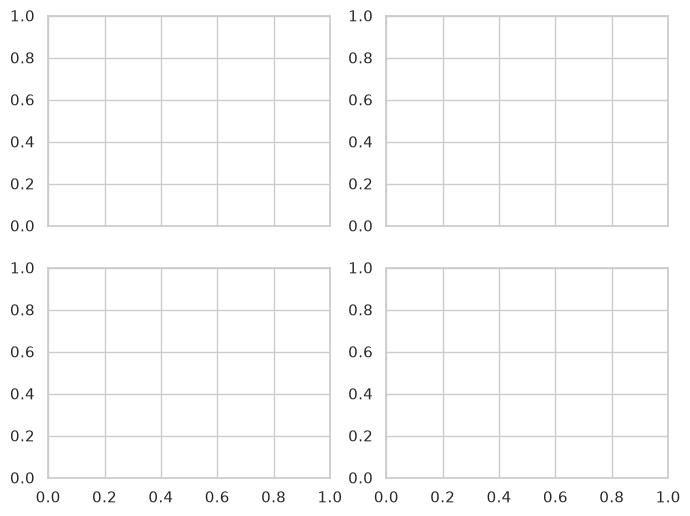

In [6]:
# plt.subplots(rows, cols) creates ONE figure (the whole canvas) and a grid of Axes
# (the individual plot areas inside it). It returns two things:
#   fig  -> the Figure object (used for whole-figure things: size, spacing, saving)
#   axes -> a 2D array of Axes, so axes[row, col] picks one panel
# Parameters:
#   2, 2         -> 2 rows and 2 columns = 4 panels
#   figsize=(8, 6) -> width 8 inches, height 6 inches
#   sharex=True  -> all panels use the SAME x axis range, so zooming/limits match
#                   and the panels are easy to compare one above the other
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)

In [7]:
check("1.1", lambda: len(fig.axes) == 4 and axes.shape == (2, 2) and tuple(fig.get_size_inches()) == (8.0, 6.0)
      and axes[0, 0].get_shared_x_axes().joined(axes[0, 0], axes[1, 1])
      and axes[0, 0].get_shared_x_axes().joined(axes[0, 0], axes[1, 0]))

Task 1.1: PASS


### Task 1.2 (5 pts): Format string

On the **top left** axes `axes[0, 0]` plot `walk` with the format string `"ko--"`.

In [8]:
# axes[0, 0] = row 0, column 0 = the TOP LEFT panel.
# .plot(y) with only one array: matplotlib uses 0, 1, 2, ... as the x values automatically.
# "ko--" is a format string, a short way to describe the look of the line:
#   k  -> colour black   (b=blue, g=green, r=red, k=black ...)
#   o  -> circle markers at every data point
#   -- -> dashed line between the points
axes[0, 0].plot(walk, "ko--")

Task 1.2: PASS


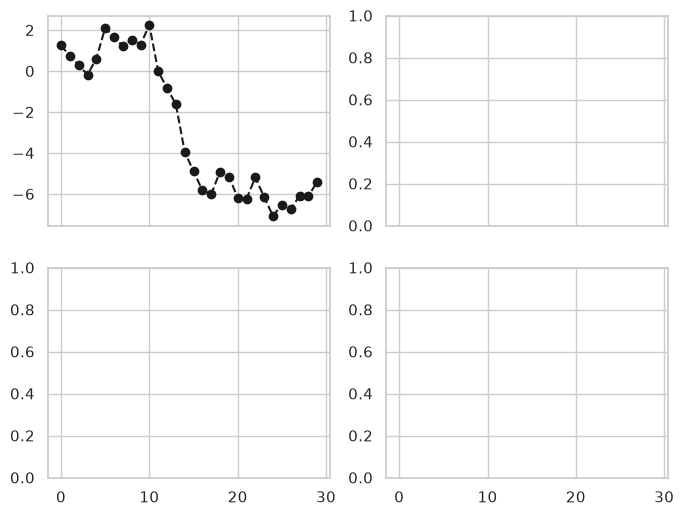

In [9]:
def _t12():
    lines = axes[0, 0].lines
    return (len(lines) == 1 and lines[0].get_color() == "k" and lines[0].get_marker() == "o"
            and lines[0].get_linestyle() == "--" and np.allclose(lines[0].get_ydata(), walk))
check("1.2", _t12)
fig

### Task 1.3 (5 pts): drawstyle and legend

On the **top right** axes `axes[0, 1]` draw `walk` twice:

1. black dashed line `"k--"` with `label="Default"`
2. black solid line `"k-"` with `drawstyle="steps-post"` and `label="steps-post"`

Then add a legend with `loc="best"`.

In [10]:
ax = axes[0, 1]   # TOP RIGHT panel; a short name so we do not repeat axes[0, 1]

# Line 1: the normal way of drawing, points are connected by straight (here dashed) lines.
#   "k--"  -> black dashed line
#   label= -> the text that will appear in the legend for this line
ax.plot(walk, "k--", label="Default")

# Line 2: the same data drawn as "steps".
#   "k-"                  -> black solid line
#   drawstyle="steps-post" -> instead of a slanted line between two points, the value stays
#                             flat until the next point and then jumps up/down (like stairs).
#                             "post" means the jump happens AFTER the point (at the next x).
ax.plot(walk, "k-", drawstyle="steps-post", label="steps-post")

# legend() collects the label= of every line and shows a small box explaining them.
# loc="best" lets matplotlib choose the corner where the box covers the least data.
ax.legend(loc="best")

Task 1.3: PASS


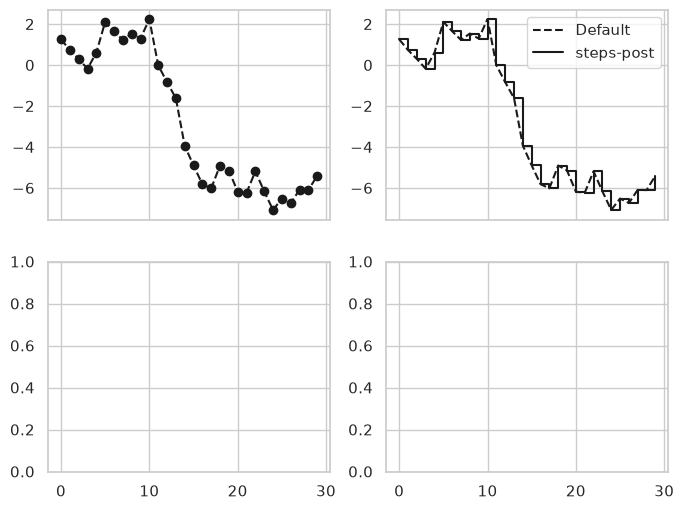

In [11]:
def _t13():
    ax = axes[0, 1]
    lines = ax.lines
    leg = ax.get_legend()
    return (len(lines) == 2 and lines[1].get_drawstyle() == "steps-post" and leg is not None
            and [t.get_text() for t in leg.get_texts()] == ["Default", "steps-post"])
check("1.3", _t13)
fig

### Task 1.4 (4 pts): Histogram

On the **bottom right** axes `axes[1, 1]` draw a histogram of `noise` with `bins=20`, `color="k"` and `alpha=0.3`.

In [12]:
# A histogram splits the range of values into intervals ("bins") and draws a bar
# whose height = how many values fall into that interval.
#   noise      -> the 100 numbers we want to describe
#   bins=20    -> split the range into 20 equal intervals (20 bars)
#   color="k"  -> black bars
#   alpha=0.3  -> transparency: 0 = invisible, 1 = solid. 0.3 makes the bars light grey
axes[1, 1].hist(noise, bins=20, color="k", alpha=0.3)

(array([ 2.,  1.,  2.,  3.,  5.,  9.,  4.,  3.,  2.,  9., 13.,  7.,  9.,
         6.,  6.,  7.,  5.,  1.,  5.,  1.]),
 array([ 3.59631077,  4.67868415,  5.76105752,  6.8434309 ,  7.92580427,
         9.00817764, 10.09055102, 11.17292439, 12.25529777, 13.33767114,
        14.42004451, 15.50241789, 16.58479126, 17.66716464, 18.74953801,
        19.83191138, 20.91428476, 21.99665813, 23.07903151, 24.16140488,
        25.24377825]),
 <BarContainer object of 20 artists>)

Task 1.4: PASS


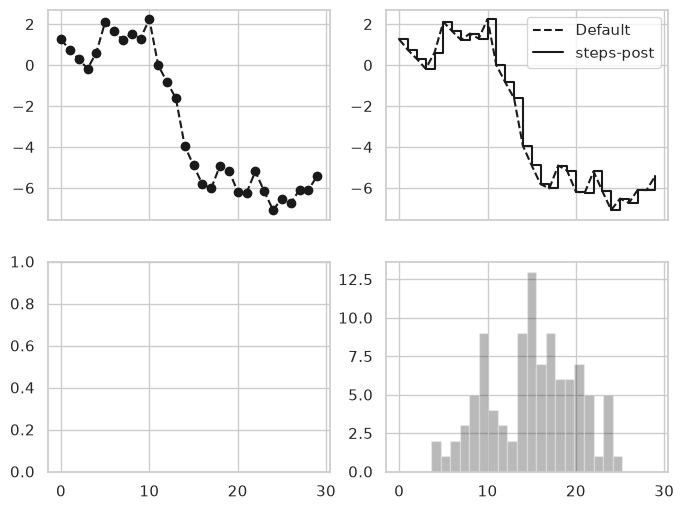

In [13]:
check("1.4", lambda: len(axes[1, 1].patches) == 20 and axes[1, 1].patches[0].get_alpha() == 0.3
      and sum(p.get_height() for p in axes[1, 1].patches) == len(noise))
fig

### Task 1.5 (4 pts): Scatter and spacing

1. On the **bottom left** axes `axes[1, 0]` draw a scatter plot of `xs` against `ys`.
2. Adjust the spacing of the whole figure: `wspace=0.3` and `hspace=0.4` (use the **figure** method `fig.subplots_adjust`).

In [62]:
# BOTTOM LEFT panel: a scatter plot draws one dot per (x, y) pair, with NO line between them.
# It is used to see whether two variables are related.
axes[1, 0].scatter(xs, ys)

# subplots_adjust changes the gaps between the panels of the whole figure (so it is a fig method).
#   wspace=0.3 -> horizontal gap between columns (width space), as a share of the panel width
#   hspace=0.4 -> vertical gap between rows (height space), as a share of the panel height
fig.subplots_adjust(wspace=0.3, hspace=0.4)

Task 1.5: PASS


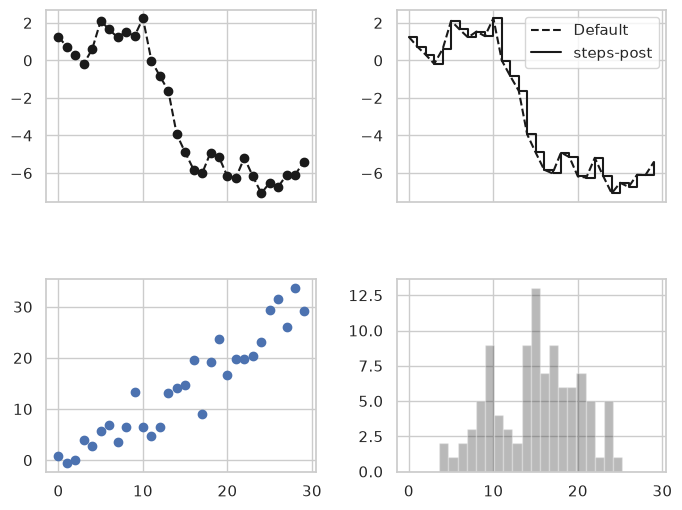

In [15]:
check("1.5", lambda: len(axes[1, 0].collections) == 1 and len(axes[1, 0].collections[0].get_offsets()) == 30
      and fig.subplotpars.wspace == 0.3 and fig.subplotpars.hspace == 0.4)
fig

---
# Part 2. Titles, labels, ticks, annotations, saving (20 points)

| Goal | Code |
|---|---|
| title and axis names | `ax.set_title("...")`, `ax.set_xlabel("...")`, `ax.set_ylabel("...")` or `ax.set(title=..., xlabel=..., ylabel=...)` |
| tick positions, then labels | `ax.set_xticks([...])`, `ax.set_xticklabels([...], rotation=45)` |
| annotation with an arrow | `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(facecolor="black", shrink=0.05))` |
| save | `fig.savefig("name.png", dpi=200, bbox_inches="tight")` |

The next cell draws the North revenue. The x positions are `0..11` and the months are `months`.

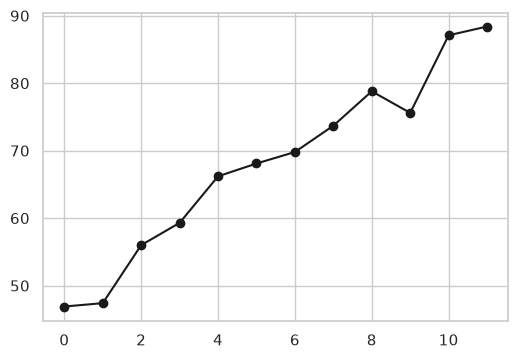

In [16]:
fig_n, ax_n = plt.subplots(figsize=(6, 4))
ax_n.plot(range(12), monthly["North"], "k-o", label="North")

### Theory: making a plot readable

| What | Method | Note |
|---|---|---|
| title, axis names | `ax.set_title("t")`, `ax.set_xlabel("x")`, `ax.set_ylabel("y")` | or all at once: `ax.set(title="t", xlabel="x", ylabel="y")` |
| tick positions | `ax.set_xticks([0, 1, 2])` | numbers where the ticks are |
| tick texts | `ax.set_xticklabels(["a", "b", "c"], rotation=45)` | **after** `set_xticks`, same number of items |
| annotation | `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(facecolor="black", shrink=0.05))` | `xy` = point, `xytext` = where the text sits |
| save | `fig.savefig("name.png", dpi=200, bbox_inches="tight")` | format comes from the extension; `dpi` * inches = pixels |

### Example (run it and change something)

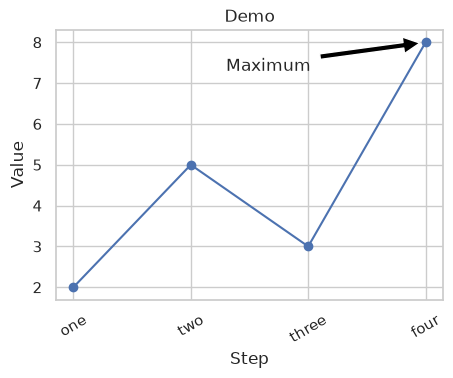

In [64]:
ex_fig, ex_ax = plt.subplots(figsize=(5, 3.5))
ex_ax.plot([2, 5, 3, 8], "b-o")
ex_ax.set(title="Demo", xlabel="Step", ylabel="Value")
ex_ax.set_xticks([0, 1, 2, 3])
ex_ax.set_xticklabels(["one", "two", "three", "four"], rotation=30)
ex_ax.annotate("Maximum", xy=(3, 8), xytext=(1.3, 7.3), arrowprops=dict(facecolor="black", shrink=0.05))
ex_fig.savefig("demo_example.png", dpi=100, bbox_inches="tight")   # 5 inches * 100 dpi = about 500 pixels

### Task 2.1 (5 pts): Title, axis names, legend

On `ax_n` set:

* title `"North region revenue"`
* x label `"Month"`
* y label `"Revenue, million KZT"`

and show the legend.

In [18]:
# Text that explains the plot. Each method changes one thing on the Axes ax_n:
ax_n.set_title("North region revenue")       # title above the plot
ax_n.set_xlabel("Month")                     # name under the x axis
ax_n.set_ylabel("Revenue, million KZT")      # name next to the y axis (always add units!)

# The line was drawn with label="North", so legend() can show it in a small box.
ax_n.legend()

Task 2.1: PASS


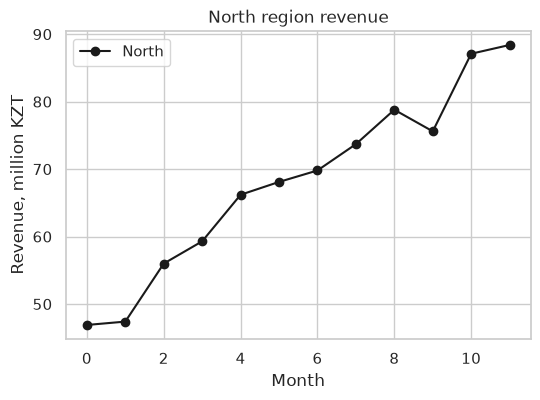

In [19]:
check("2.1", lambda: ax_n.get_title() == "North region revenue" and ax_n.get_xlabel() == "Month"
      and ax_n.get_ylabel() == "Revenue, million KZT" and ax_n.get_legend() is not None)
fig_n

### Task 2.2 (5 pts): Ticks and tick labels

Put a tick at every position `0..11` and write the month names (`months`) there, rotated by **45 degrees**.
Remember: first `set_xticks`, then `set_xticklabels`.

In [20]:
# Ticks are the small marks on an axis; tick labels are the texts written at those marks.
# Step 1: set_xticks -> WHERE the ticks are. Our points are at x = 0, 1, ..., 11, so we put
#         one tick at every point. range(12) gives exactly 0..11.
ax_n.set_xticks(range(12))

# Step 2: set_xticklabels -> WHAT is written at those ticks, one text per tick (12 month names).
#   rotation=45 -> turn the texts 45 degrees so long labels do not overlap each other.
# It must come AFTER set_xticks, otherwise matplotlib does not know how many/where the ticks are.
ax_n.set_xticklabels(months, rotation=45)

[Text(0, 0, 'Jan'),
 Text(1, 0, 'Feb'),
 Text(2, 0, 'Mar'),
 Text(3, 0, 'Apr'),
 Text(4, 0, 'May'),
 Text(5, 0, 'Jun'),
 Text(6, 0, 'Jul'),
 Text(7, 0, 'Aug'),
 Text(8, 0, 'Sep'),
 Text(9, 0, 'Oct'),
 Text(10, 0, 'Nov'),
 Text(11, 0, 'Dec')]

Task 2.2: PASS


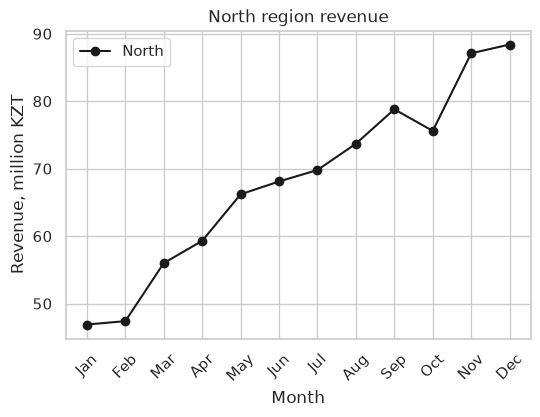

In [21]:
check("2.2", lambda: list(ax_n.get_xticks()) == list(range(12))
      and [t.get_text() for t in ax_n.get_xticklabels()] == months
      and ax_n.get_xticklabels()[0].get_rotation() == 45)
fig_n

### Task 2.3 (5 pts): Annotate the peak

1. `peak_idx`: the **position** (0 to 11) of the month with the highest North revenue
2. `peak_val`: that highest revenue
3. Add an annotation with the text `"Peak"` that points (`xy`) at the peak. Move the text away with `xytext` and draw an arrow
   with `arrowprops`.

*Hint:* `monthly["North"].argmax()` or `.to_numpy().argmax()`; `.max()`.

In [22]:
# argmax() returns the POSITION (0..11) of the largest value, not the value itself.
# int(...) turns the numpy number into a normal Python integer.
peak_idx = int(monthly["North"].argmax())

# max() returns the largest value itself.
peak_val = monthly["North"].max()

# annotate() writes a text and (optionally) draws an arrow from the text to a point.
#   "Peak"        -> the text to show
#   xy=(...)      -> the point the arrow points AT (x = month position, y = revenue)
#   xytext=(...)  -> where the TEXT is placed; here 2 months to the left and a bit lower,
#                    so the text does not cover the line
#   arrowprops    -> a dictionary that describes the arrow; without it no arrow is drawn
#       facecolor="black" -> fill colour of the arrow
#       shrink=0.05       -> make the arrow 5% shorter at both ends so it does not touch the text/point
ax_n.annotate("Peak",
              xy=(peak_idx, peak_val),
              xytext=(peak_idx - 2, peak_val - 3),
              arrowprops=dict(facecolor="black", shrink=0.05))

Text(9, 85.4, 'Peak')

Task 2.3: PASS


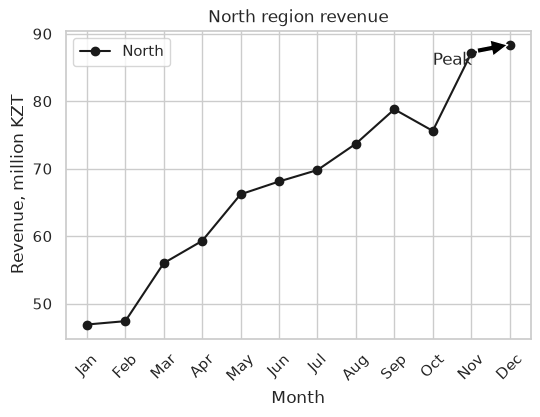

In [23]:
def _t23():
    anns = [t for t in ax_n.texts if isinstance(t, Annotation)]
    return (peak_idx == int(monthly["North"].to_numpy().argmax()) and peak_val == monthly["North"].max()
            and len(anns) == 1 and anns[0].get_text() == "Peak" and np.allclose(anns[0].xy, (peak_idx, peak_val))
            and anns[0].arrow_patch is not None)
check("2.3", _t23)
fig_n

### Task 2.4 (5 pts): Save the figure

Save `fig_n` to the file `north_revenue.png` with **dpi=200** and `bbox_inches="tight"`.

In [24]:
# savefig writes the figure to a file. The file format comes from the extension (.png).
#   dpi=200            -> "dots per inch": pixel density. 6 inches wide * 200 = about 1200 pixels wide.
#   bbox_inches="tight" -> cut away the empty white border around the plot
#                          (and make sure rotated labels are not cut off)
fig_n.savefig("north_revenue.png", dpi=200, bbox_inches="tight")

In [25]:
def _png_width(path):
    with open(path, "rb") as f:
        head = f.read(24)
    return head[:8] == b"\x89PNG\r\n\x1a\n", int.from_bytes(head[16:20], "big")

check("2.4", lambda: os.path.exists("north_revenue.png") and _png_width("north_revenue.png")[0]
      and _png_width("north_revenue.png")[1] > 1000)   # 6 inches * 200 dpi is about 1200 pixels

Task 2.4: PASS


---
# Part 3. Plotting with pandas (24 points)

`Series.plot` and `DataFrame.plot` call matplotlib for you. The index becomes the x axis.

| Goal | Code |
|---|---|
| line plot, one line per column | `df.plot()` |
| one panel per column | `df.plot(subplots=True, sharex=True)` |
| bars: grouped, horizontal, stacked | `df.plot.bar()`, `df.plot.barh(stacked=True)` |
| histogram, density | `s.plot.hist(bins=30)`, `s.plot.density()` |
| draw on an existing axes | `s.plot.hist(ax=ax)` |

### Theory: pandas calls matplotlib for you

* `df.plot()` draws **one line per column**, the **index is the x axis**, the legend is created automatically.
* Other kinds: `df.plot.bar()` (grouped bars, one group per row), `df.plot.barh(stacked=True)` (stacked, horizontal),
  `s.plot.hist(bins=30)`, `s.plot.density()` (smoothed histogram, needs `scipy`), `s.plot.pie()`.
* `subplots=True` gives one panel per column. `ax=some_axes` draws into an axes you made yourself (that is how panels are combined).
* Every pandas plot **returns the Axes**, so you can keep customising it: `ax = df.plot(); ax.set_title("...")`.
* **Shares instead of counts:** `ct = pd.crosstab(a, b)` counts pairs; `ct.div(ct.sum(axis=1), axis=0)` divides each row by its total,
  so each row sums to 1 and rows of different size can be compared.

### Example (run it and change something)

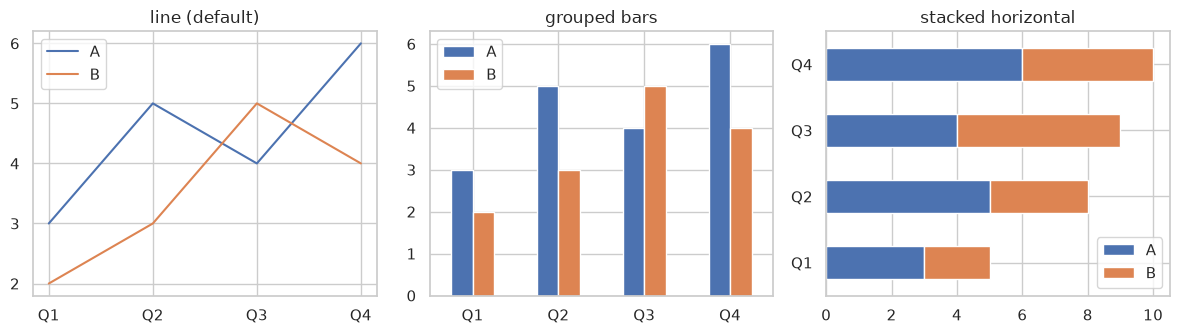

In [72]:
ex_df = pd.DataFrame({"A": [3, 5, 4, 6], "B": [2, 3, 5, 4]}, index=["Q1", "Q2", "Q3", "Q4"])
ex_fig, ex_axes = plt.subplots(1, 3, figsize=(12, 3.5))
ex_df.plot(ax=ex_axes[0], title="line (default)")                       # index on x, one line per column
ex_df.plot.bar(ax=ex_axes[1], rot=0, title="grouped bars")
ex_df.plot.barh(ax=ex_axes[2], stacked=True, title="stacked horizontal")
ex_fig.tight_layout()

### Task 3.1 (3 pts): Remove the outlier

Make `clean`: a copy of `tips` **without** rows where `tip_pct` is **1 or more** (a tip above 100 percent of the bill is an
entry error).

In [27]:
# tips["tip_pct"] < 1 gives a True/False value for every row (True = tip below 100% of the bill).
# Putting it inside tips[...] keeps only the True rows (this is called boolean filtering).
# .copy() makes a separate DataFrame, so later changes to `clean` never touch `tips`.
clean = tips[tips["tip_pct"] < 1].copy()

In [28]:
check("3.1", lambda: len(clean) == len(tips) - 1 and clean["tip_pct"].max() < 1)

Task 3.1: PASS


### Task 3.2 (4 pts): DataFrame line plot

Plot all three columns of `monthly` as lines on one axes with `monthly.plot(...)`, `figsize=(8, 4)` and
`title="Revenue by region"`. Store the returned axes in `ax_line`.

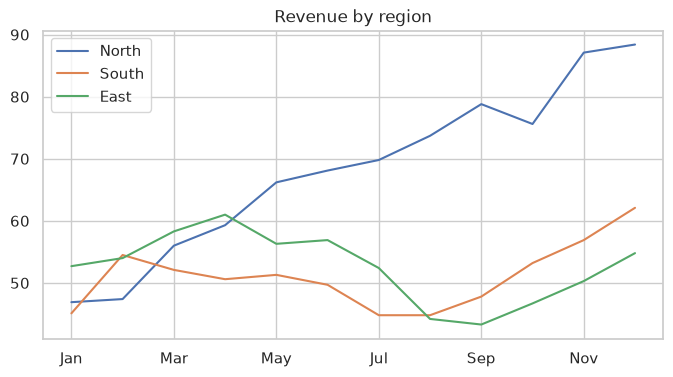

In [29]:
# DataFrame.plot() is pandas calling matplotlib for us:
#   - every COLUMN (North, South, East) becomes one line
#   - the INDEX (month names) becomes the x axis
#   - a legend with the column names is added automatically
#   figsize=(8, 4) -> size of the new figure in inches
#   title=...      -> title of the plot
# It returns the matplotlib Axes, so we store it to change/check it later.
ax_line = monthly.plot(figsize=(8, 4), title="Revenue by region")

In [30]:
check("3.2", lambda: ax_line.get_title() == "Revenue by region" and len(ax_line.lines) == 3
      and [t.get_text() for t in ax_line.get_legend().get_texts()] == ["North", "South", "East"])

Task 3.2: PASS


### Task 3.3 (3 pts): One panel per column

Plot `monthly` again, but with **each column in its own panel** sharing the x axis, `figsize=(8, 6)`.
Store the returned array of axes in `axes_sub`.

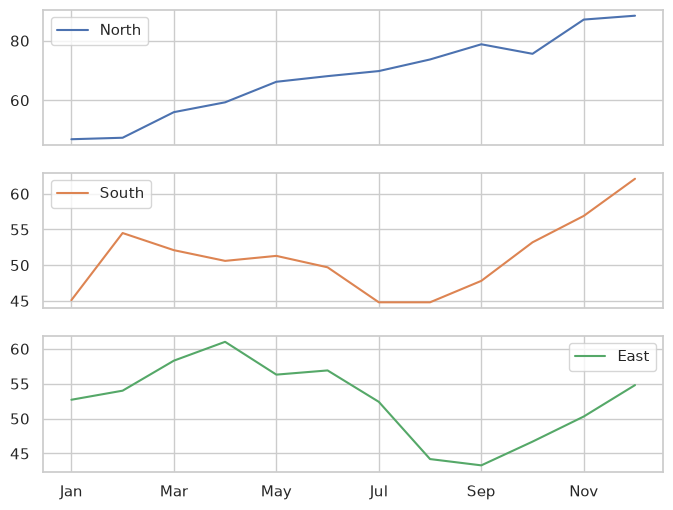

In [31]:
#   subplots=True -> instead of 3 lines on one plot, make 3 separate panels (one per column)
#   sharex=True   -> all panels use the same x axis (the months), so they line up vertically
#   figsize=(8, 6) -> size of the whole figure in inches
# With subplots=True pandas returns an ARRAY of Axes (one per column), not a single Axes.
axes_sub = monthly.plot(subplots=True, sharex=True, figsize=(8, 6))

In [32]:
check("3.3", lambda: len(axes_sub) == 3 and all(len(a.lines) == 1 for a in axes_sub)
      and tuple(axes_sub[0].figure.get_size_inches()) == (8.0, 6.0))

Task 3.3: PASS


### Task 3.4 (5 pts): Grouped bar chart

Use `clean`:

1. `avg`: the **mean `tip_pct`** for every combination of `day` (rows) and `smoker` (columns). Use `groupby` and `unstack`.
2. `ax_bar`: a grouped bar chart of `avg` with horizontal tick labels (`rot=0`).

Text(0, 0.5, 'Mean tip percentage')

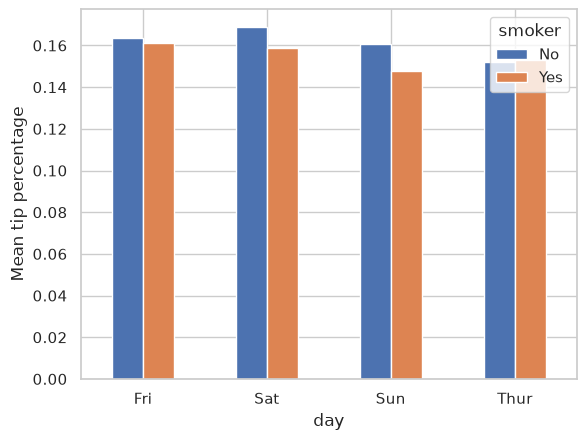

In [74]:
# Step 1: groupby(["day", "smoker"]) puts the rows into groups, one group per (day, smoker) pair,
#         e.g. ("Fri", "No"), ("Fri", "Yes"), ...
#         ["tip_pct"].mean() -> average tip percentage in each group.
#         The result is a Series with a two-level index (day, smoker).
# Step 2: unstack() moves the inner index level (smoker) into COLUMNS.
#         Now rows = days, columns = "No" / "Yes" -> a small table, easy to plot.
avg = clean.groupby(["day", "smoker"])["tip_pct"].mean().unstack()

# plot.bar() on a DataFrame draws a GROUPED bar chart:
#   one group of bars per row (day), one bar per column (No / Yes) inside every group.
#   rot=0 -> rotation of the x tick labels: 0 = horizontal (default for bar is 90 = vertical)
ax_bar = avg.plot.bar(rot=0)
ax_bar.set_ylabel("Mean tip percentage")

In [34]:
def _t34():
    expected = clean.pivot_table(index="day", columns="smoker", values="tip_pct", aggfunc="mean")
    heights = sorted(p.get_height() for p in ax_bar.patches)
    return (avg.shape == (4, 2) and np.allclose(avg.sort_index().to_numpy(), expected.sort_index().to_numpy())
            and len(ax_bar.patches) == avg.size and np.allclose(heights, sorted(avg.to_numpy().ravel()))
            and [t.get_text() for t in ax_bar.get_legend().get_texts()] == ["No", "Yes"])
check("3.4", _t34)

Task 3.4: PASS


### Task 3.5 (5 pts): Shares as stacked bars

How is the **party size** distributed on each day? Use `clean`:

1. `ct`: `pd.crosstab` of `day` (rows) and `size` (columns), counts.
2. `shares`: divide every row of `ct` by its row total, so that each **row sums to 1**
   (`ct.div(ct.sum(axis=1), axis=0)`).
3. `ax_share`: a **horizontal stacked** bar chart of `shares`.

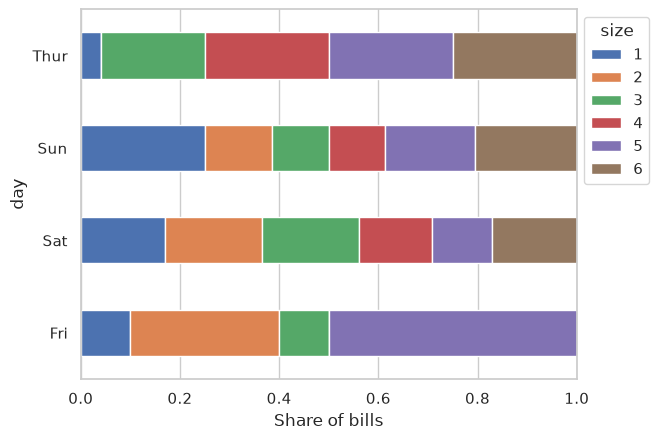

In [35]:
# pd.crosstab(rows, columns) COUNTS how many times every pair occurs.
# Here: for each day (rows) how many parties of size 1, 2, ..., 6 (columns) came.
ct = pd.crosstab(clean["day"], clean["size"])

# Counts are hard to compare because days have different numbers of bills.
# So we turn counts into SHARES:
#   ct.sum(axis=1)  -> total number of bills in every row (every day)
#   ct.div(..., axis=0) -> divide each row by its own total (axis=0 = match by row labels)
# After this every row adds up to 1 (= 100%).
shares = ct.div(ct.sum(axis=1), axis=0)

# plot.barh -> HORIZONTAL bars (one bar per day).
# stacked=True -> instead of placing bars side by side, the pieces (party sizes) are put
#                 one after another inside one long bar. Since each row sums to 1,
#                 every bar has length 1 and the pieces show the share of each party size.
ax_share = shares.plot.barh(stacked=True)
ax_share.set_xlabel("Share of bills")

# Move the legend outside the plot on the right so it does not cover the bars.
#   title="size"          -> heading of the legend box
#   bbox_to_anchor=(1, 1) -> place the legend's corner at the top right edge of the axes
#   loc="upper left"      -> which corner of the legend is put at that point
ax_share.legend(title="size", bbox_to_anchor=(1, 1), loc="upper left")

In [36]:
check("3.5", lambda: ct.to_numpy().sum() == len(clean) and np.allclose(shares.sum(axis=1), 1)
      and len(ax_share.patches) == shares.size and ax_share.get_xlim()[1] < 1.1)

Task 3.5: PASS


### Task 3.6 (4 pts): Histogram and density

Create `fig_h, axes_h = plt.subplots(1, 2, figsize=(10, 4))`. Then plot the `tip_pct` of **`clean`** with pandas:

* left axes: histogram with `bins=30`
* right axes: density plot

*Hint:* pass `ax=axes_h[0]` and `ax=axes_h[1]`. The density plot needs `scipy`.

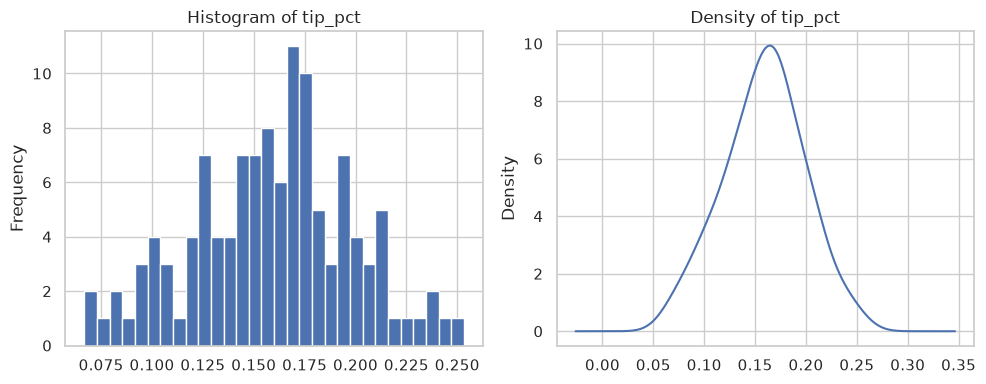

In [37]:
# One figure with 1 row and 2 columns -> axes_h is a 1D array: axes_h[0] (left), axes_h[1] (right).
fig_h, axes_h = plt.subplots(1, 2, figsize=(10, 4))

# Left: histogram of the tip percentage.
#   bins=30     -> 30 intervals
#   ax=axes_h[0] -> draw into OUR left panel instead of creating a new figure
clean["tip_pct"].plot.hist(bins=30, ax=axes_h[0], title="Histogram of tip_pct")

# Right: density plot = a smooth curve version of the histogram
# (it estimates how likely each value is; the area under the curve is 1). Needs scipy.
clean["tip_pct"].plot.density(ax=axes_h[1], title="Density of tip_pct")

# tight_layout automatically adds space so titles/labels of the two panels do not overlap.
fig_h.tight_layout()

In [38]:
check("3.6", lambda: len(axes_h[0].patches) == 30 and sum(p.get_height() for p in axes_h[0].patches) == len(clean)
      and len(axes_h[1].lines) == 1)

Task 3.6: PASS


---
# Part 4. Plotting with seaborn (15 points)

seaborn works on top of matplotlib and understands DataFrames: you give `data=...` and column **names**.

| Goal | Code |
|---|---|
| bars with mean and error bar, split by a category | `sns.barplot(data=df, x=..., y=..., hue=...)` |
| scatter with a fitted regression line | `sns.regplot(data=df, x=..., y=...)` |
| box plot per category | `sns.boxplot(data=df, x=..., y=...)` |
| heatmap of a matrix (for example correlations) | `sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)` |

All these functions return the matplotlib `Axes`, so you can continue with `ax.set_title(...)`.
Use `clean` from Part 3. If `import seaborn` failed in the setup cell, run `pip install seaborn` and restart the kernel.

### Theory: seaborn

* seaborn draws **statistical** plots straight from a DataFrame: you pass `data=df` and **column names** as strings.
* **`hue`** splits the data by a category (one colour per category, a legend appears).
* `barplot` shows the **mean** of `y` per `x` with an error bar (95 percent confidence interval); `boxplot` shows median, quartiles, whiskers and outliers;
  `regplot` shows a scatter plus a fitted line with a confidence band; `heatmap` shows a matrix as colours (`annot=True` writes the numbers).
* Each function returns an `Axes`: you can call `ax.set_title(...)` afterwards. `order=[...]` fixes the order of categories.
* Correlation `r` is between -1 and 1: near 1 the variables grow together, near -1 one grows while the other falls, near 0 no linear relation.
  It does not prove that one variable *causes* the other.

### Example (run it and change something)

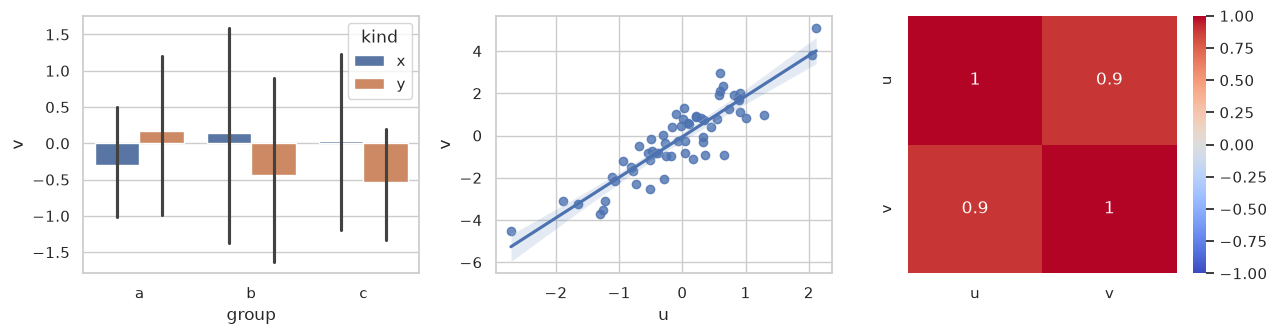

In [39]:
ex_rng = np.random.default_rng(1)
ex_data = pd.DataFrame({"group": np.repeat(["a", "b", "c"], 20), "kind": np.tile(["x", "y"], 30),
                        "u": ex_rng.normal(size=60)})
ex_data["v"] = 2 * ex_data["u"] + ex_rng.normal(size=60)
ex_fig, ex_axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.barplot(data=ex_data, x="group", y="v", hue="kind", ax=ex_axes[0])      # ax= draws into your own axes
sns.regplot(data=ex_data, x="u", y="v", ax=ex_axes[1])
sns.heatmap(ex_data[["u", "v"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ex_axes[2])
ex_fig.tight_layout()

### Task 4.1 (4 pts): barplot with hue

`ax_sns`: a bar plot of the mean `tip_pct` (y) for each `day` (x) split by `time` (`hue`). Use the order
`["Thur", "Fri", "Sat", "Sun"]` for the days.

<Axes: xlabel='day', ylabel='tip_pct'>

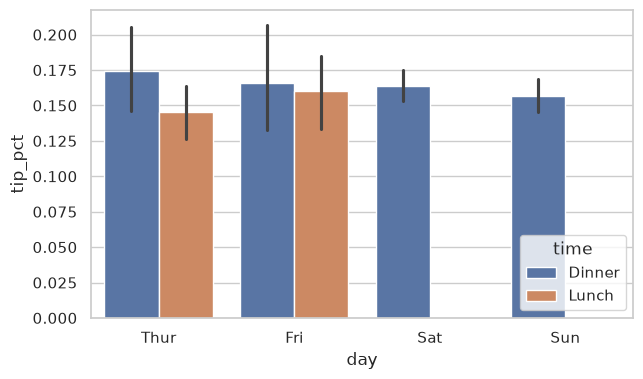

In [40]:
# We create our own figure + axes (object-oriented style) and tell seaborn to draw into it with ax=.
fig_sns, ax_sns = plt.subplots(figsize=(7, 4))

# sns.barplot draws, for every x category, a bar whose height = MEAN of y in that category,
# plus a thin black "error bar" showing the uncertainty of that mean (95% confidence interval).
#   data=clean   -> the DataFrame to use; then columns are given just by their NAME (a string)
#   x="day"      -> categories on the x axis
#   y="tip_pct"  -> the value whose mean is shown
#   hue="time"   -> split every day into Lunch / Dinner with different colours (+ legend titled "time")
#   order=[...]  -> the order of the days on the x axis (otherwise seaborn uses the order it meets them)
#   ax=ax_sns    -> draw into our axes
sns.barplot(data=clean, x="day", y="tip_pct", hue="time",
            order=["Thur", "Fri", "Sat", "Sun"], ax=ax_sns)

In [41]:
check("4.1", lambda: ax_sns.get_xlabel() == "day" and ax_sns.get_ylabel() == "tip_pct"
      and [t.get_text() for t in ax_sns.get_xticklabels()] == ["Thur", "Fri", "Sat", "Sun"]
      and ax_sns.get_legend().get_title().get_text() == "time")

Task 4.1: PASS


### Task 4.2 (4 pts): regplot

`ax_reg`: a regression plot of `tip` (y) against `total_bill` (x), then set its title to `"Tip versus bill"`.

Text(0.5, 1.0, 'Tip versus bill')

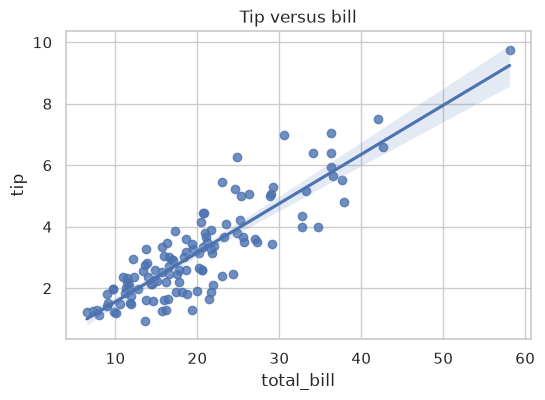

In [42]:
fig_reg, ax_reg = plt.subplots(figsize=(6, 4))

# sns.regplot = scatter plot + a fitted straight line (linear regression) + a shaded band
# around the line (95% confidence interval: where the true line probably lies).
#   x="total_bill" -> horizontal axis
#   y="tip"        -> vertical axis
# If the points follow the line upward, bigger bills tend to have bigger tips.
sns.regplot(data=clean, x="total_bill", y="tip", ax=ax_reg)

# seaborn returns/uses a normal matplotlib Axes, so normal matplotlib methods work on it.
ax_reg.set_title("Tip versus bill")

In [43]:
check("4.2", lambda: ax_reg.get_title() == "Tip versus bill" and ax_reg.get_xlabel() == "total_bill"
      and len(ax_reg.lines) == 1 and len(ax_reg.collections[0].get_offsets()) == len(clean))

Task 4.2: PASS


### Task 4.3 (3 pts): boxplot

`ax_box`: a **horizontal** box plot of `tip_pct` (x) by `day` (y) with the order `["Thur", "Fri", "Sat", "Sun"]`.

<Axes: xlabel='tip_pct', ylabel='day'>

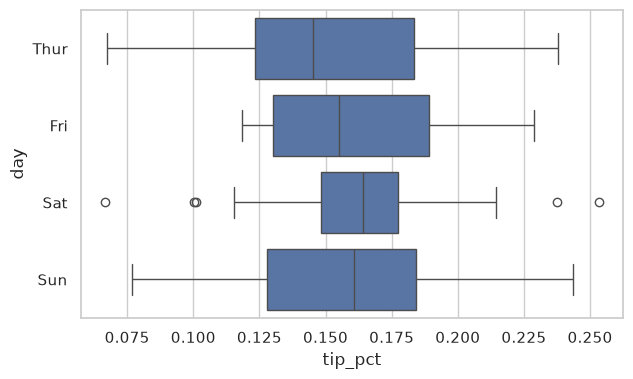

In [44]:
fig_box, ax_box = plt.subplots(figsize=(7, 4))

# sns.boxplot summarises a distribution per category:
#   box          -> the middle 50% of values (from the 25th to the 75th percentile)
#   line in box  -> the median (middle value)
#   whiskers     -> the normal range of the data (up to 1.5 * box length from the box)
#   single dots  -> outliers (values outside the whiskers)
# Putting the NUMBERS on x (x="tip_pct") and the CATEGORY on y (y="day")
# makes seaborn draw the boxes HORIZONTALLY.
#   order=[...] -> order of the days on the y axis
sns.boxplot(data=clean, x="tip_pct", y="day",
            order=["Thur", "Fri", "Sat", "Sun"], ax=ax_box)

In [45]:
check("4.3", lambda: ax_box.get_xlabel() == "tip_pct" and ax_box.get_ylabel() == "day"
      and [t.get_text() for t in ax_box.get_yticklabels()] == ["Thur", "Fri", "Sat", "Sun"] and len(ax_box.lines) > 0)

Task 4.3: PASS


### Task 4.4 (4 pts): Heatmap of correlations

1. `corr`: the correlation matrix of the columns `["total_bill", "tip", "size", "tip_pct"]` of `clean` (`.corr()`).
2. `ax_heat`: a heatmap of `corr` with the numbers written in the cells (`annot=True`), `cmap="coolwarm"`,
   and the colour scale fixed from `-1` to `1` (`vmin`, `vmax`).

Text(0.5, 1.0, 'Correlation matrix')

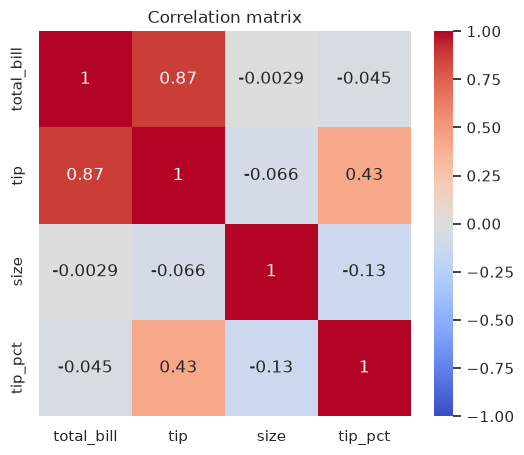

In [46]:
# .corr() computes the correlation between every pair of the chosen columns.
# The result is a 4 x 4 table; each value is between -1 and 1:
#   close to 1  -> the two columns grow together
#   close to -1 -> one grows while the other falls
#   close to 0  -> no linear relationship
corr = clean[["total_bill", "tip", "size", "tip_pct"]].corr()

fig_heat, ax_heat = plt.subplots(figsize=(6, 5))

# sns.heatmap shows a table as coloured squares (colour = value).
#   annot=True       -> also write the number inside every square
#   cmap="coolwarm"  -> colour scheme: blue = negative, white = 0, red = positive
#   vmin=-1, vmax=1  -> fix the colour scale to the full correlation range, so that the
#                       colours mean the same thing on every heatmap (not stretched to the data)
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax_heat)
ax_heat.set_title("Correlation matrix")

In [47]:
def _t44():
    cols = ["total_bill", "tip", "size", "tip_pct"]
    return (corr.shape == (4, 4) and np.allclose(corr.to_numpy(), clean[cols].corr().to_numpy())
            and len(ax_heat.texts) == 16 and ax_heat.collections[0].get_clim() == (-1.0, 1.0)
            and [t.get_text() for t in ax_heat.get_xticklabels()] == cols)
check("4.4", _t44)

Task 4.4: PASS


---
# Part 5. Mini project: dashboard on regions of Kazakhstan (19 points)

Build **one figure with four panels** about the population of Kazakhstan. Data: `kz` (area, population in 2009 and 2022).
Only rows with `kind == "region"` are used: the cities of national status (Almaty, Astana, Shymkent) and Baikonur are excluded.

| Position | Panel |
|---|---|
| top left | horizontal bar chart: population 2022 of the **5 largest** regions |
| top right | pie chart: share of those 5 regions and of everybody else (`Other`) |
| bottom left | scatter: area (x) against population 2022 (y), the most populated region is annotated |
| bottom right | horizontal bar chart: population growth 2009 to 2022 in percent, for all regions |

### Theory: a dashboard and the "top N + Other" pattern

* A **dashboard** is one figure with several panels that answer one business question. Build it with `fig, axes = plt.subplots(2, 2, figsize=(...))`,
  draw into `axes[i, j]` (pandas: `ax=axes[i, j]`), give **every panel its own title and axis names**, then
  `fig.suptitle("...")`, `fig.tight_layout()` and `fig.savefig(...)`.
* A **pie chart** shows parts of **one whole**: `s.plot.pie(autopct="%1.1f%%", startangle=90)`. With many categories the small slices become unreadable,
  so keep the **top N** (`s.nlargest(N)`) and merge the rest into one slice `Other`.
  When you need to compare many categories precisely, use a bar chart instead.
* Growth in percent: `(new / old - 1) * 100`.

### Example: top N + Other (run it and change N)

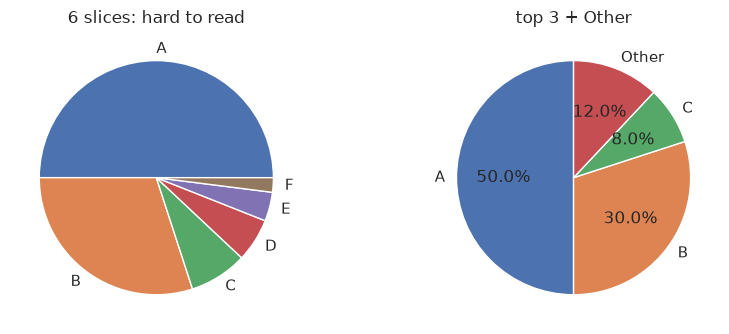

In [48]:
ex_pop = pd.Series({"A": 50, "B": 30, "C": 8, "D": 6, "E": 4, "F": 2})
ex_top = ex_pop.nlargest(3)
ex_share = pd.concat([ex_top, pd.Series({"Other": ex_pop.sum() - ex_top.sum()})])      # top 3 + one slice for the rest
ex_fig, ex_axes = plt.subplots(1, 2, figsize=(9, 3.5))
ex_pop.plot.pie(ax=ex_axes[0], title="6 slices: hard to read")
ex_share.plot.pie(ax=ex_axes[1], autopct="%1.1f%%", startangle=90, title="top 3 + Other")
ex_fig.tight_layout()

### Task 5.1 (3 pts): Prepare the data

1. `regions`: a copy of `kz` with only `kind == "region"` rows, plus a new column `growth_pct` = `(pop_2022 / pop_2009 - 1) * 100`.
2. `top5`: a Series with the `pop_2022` of the **5 most populated** regions, index = region name (`nlargest`, `set_index`).
3. `share`: `top5` plus one more element `"Other"` = population of all the other regions (`pd.concat` with a one-element Series).

In [49]:
# 1) Keep only real regions (drop the cities). kz["kind"] == "region" is True/False per row.
#    .copy() so we can safely add a new column.
regions = kz[kz["kind"] == "region"].copy()

# Growth in percent: new / old gives e.g. 1.25 (= 25% more); minus 1 -> 0.25; times 100 -> 25.
# The calculation is done for all rows at once (pandas works on whole columns).
regions["growth_pct"] = (regions["pop_2022"] / regions["pop_2009"] - 1) * 100

# 2) nlargest(5, "pop_2022") -> the 5 rows with the largest 2022 population.
#    set_index("region")     -> region names become the index (they will be the bar/pie labels)
#    ["pop_2022"]            -> keep only that column -> a Series: name -> population
top5 = regions.nlargest(5, "pop_2022").set_index("region")["pop_2022"]

# 3) "Other" = everybody who is NOT in the top 5 = total of all regions minus the top 5.
#    pd.Series({"Other": value}) makes a one-element Series; pd.concat glues it after top5.
other = regions["pop_2022"].sum() - top5.sum()
share = pd.concat([top5, pd.Series({"Other": other})])
share

Turkistan        2110502
Almaty Region    1497025
Jambyl           1215482
Karaganda        1134146
Aqtobe            924845
Other            8137850
dtype: int64

In [50]:
def _t51():
    exp_top = regions.sort_values("pop_2022", ascending=False).head(5)
    return (len(regions) == 17 and set(regions["kind"]) == {"region"}
            and np.allclose(regions["growth_pct"], (regions["pop_2022"] / regions["pop_2009"] - 1) * 100)
            and list(top5.index) == list(exp_top["region"]) and len(share) == 6 and share.index[-1] == "Other"
            and share.sum() == regions["pop_2022"].sum())
check("5.1", _t51)

Task 5.1: PASS


### Task 5.2 (4 pts): Figure, bar panel and pie panel

1. `dash, dax = ...`: a 2 by 2 figure of size `(12, 9)`.
2. **Top left**: horizontal bar chart of `top5` **sorted ascending** (`sort_values()`), so that the largest bar is on top:
   `top5.sort_values().plot.barh(ax=...)`.
3. **Top right**: pie chart of `share` with percentages (`autopct="%1.1f%%"`) and `startangle=90`:
   `share.plot.pie(ax=..., ...)`.

<Axes: >

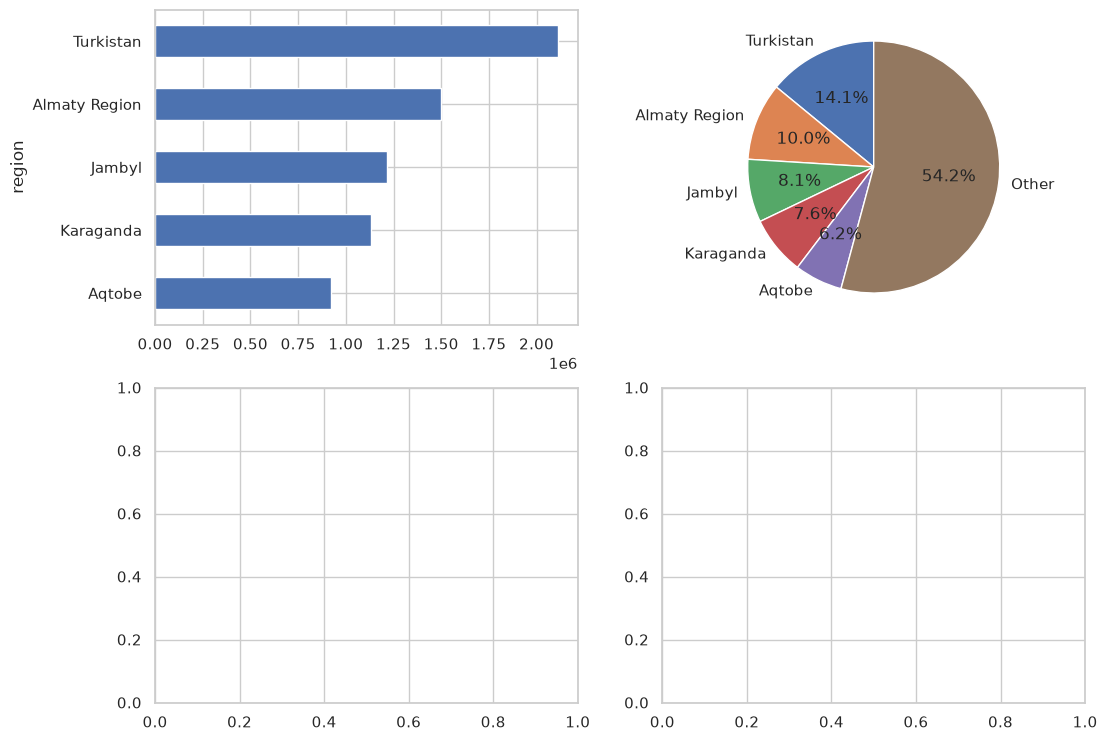

In [51]:
# The dashboard: one figure, 2 x 2 panels, 12 x 9 inches (big, because 4 panels share it).
# dax[row, col] picks a panel.
dash, dax = plt.subplots(2, 2, figsize=(12, 9))

# TOP LEFT: horizontal bar chart of the 5 largest regions.
# sort_values() sorts ascending (smallest first). barh draws the first item at the BOTTOM,
# so the largest region ends up at the TOP, which is how people read rankings.
top5.sort_values().plot.barh(ax=dax[0, 0])

# TOP RIGHT: pie chart = parts of one whole (all regions = 100%).
#   autopct="%1.1f%%" -> write the percentage on each slice with 1 digit after the point
#                        (%1.1f = number format, %% = a literal % sign)
#   startangle=90     -> start the first slice at the top (12 o'clock) instead of 3 o'clock
share.plot.pie(ax=dax[0, 1], autopct="%1.1f%%", startangle=90)

In [52]:
def _t52():
    bars = [p.get_width() for p in dax[0, 0].patches]
    return (len(dash.axes) == 4 and tuple(dash.get_size_inches()) == (12.0, 9.0)
            and len(bars) == 5 and bars == sorted(bars) and np.allclose(sorted(bars), sorted(top5.to_numpy()))
            and len(dax[0, 1].patches) == 6 and any("%" in t.get_text() for t in dax[0, 1].texts))
check("5.2", _t52)

Task 5.2: PASS


### Task 5.3 (3 pts): Scatter with an annotation

**Bottom left**: scatter of `area_km2` (x) against `pop_2022` (y) for `regions`. Then annotate the **most populated region**:
the text is its name, `xy` is its point, move the text away (`xytext` with `textcoords="offset points"`) and draw an arrow
(`arrowprops=dict(arrowstyle="->")`).

*Hint:* `regions.loc[regions["pop_2022"].idxmax()]` gives the row.

In [53]:
ax = dax[1, 0]   # BOTTOM LEFT panel

# One dot per region: x = area, y = population. Shows whether bigger regions have more people.
ax.scatter(regions["area_km2"], regions["pop_2022"])

# idxmax() gives the index (row label) of the largest pop_2022; .loc[...] takes that whole row.
big = regions.loc[regions["pop_2022"].idxmax()]

# Write the region's name next to its dot with an arrow.
#   big["region"]                 -> the text (region name)
#   xy=(area, population)         -> the dot the arrow points at (in data units)
#   xytext=(30, -30)              -> where the text goes...
#   textcoords="offset points"    -> ...measured in points FROM the dot (30 right, 30 down),
#                                    so we do not need to think about the data scale
#   arrowprops=dict(arrowstyle="->", color="black") -> draw a simple black arrow
#       (color is needed: the seaborn theme from the setup cell makes arrow lines white by default)
ax.annotate(big["region"],
            xy=(big["area_km2"], big["pop_2022"]),
            xytext=(30, -30), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="black"))

Text(30, -30, 'Turkistan')

Task 5.3: PASS


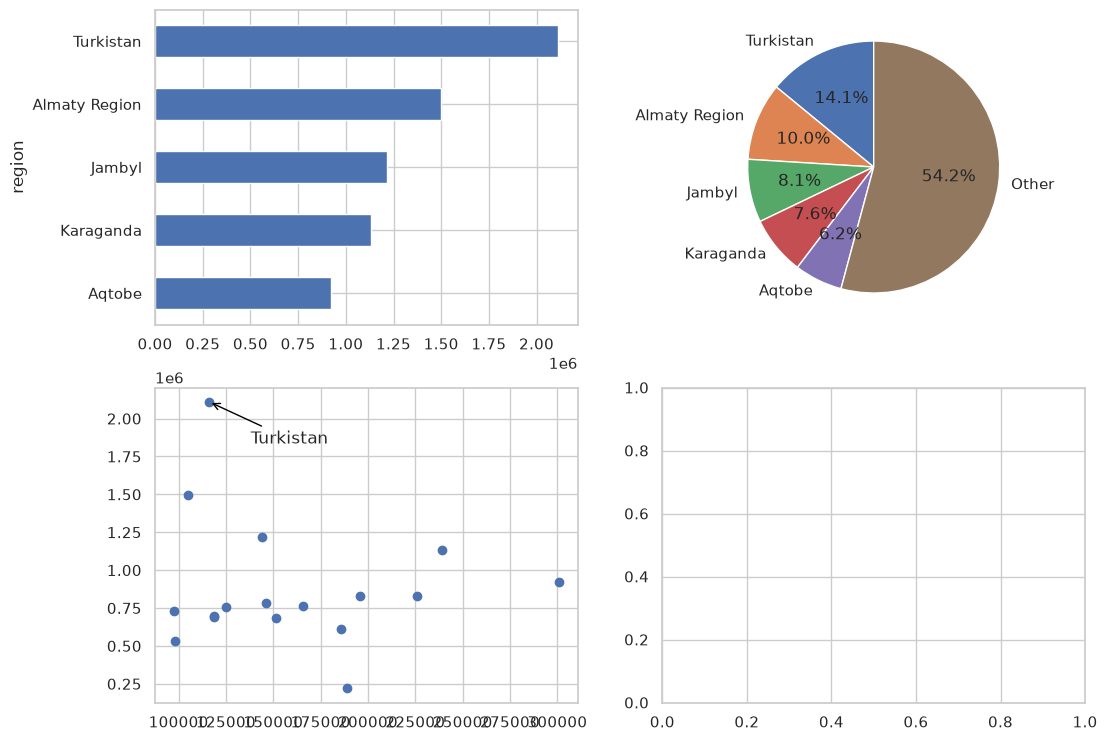

In [54]:
def _t53():
    ax = dax[1, 0]
    anns = [t for t in ax.texts if isinstance(t, Annotation)]
    big = regions.loc[regions["pop_2022"].idxmax()]
    return (len(ax.collections) == 1 and len(ax.collections[0].get_offsets()) == len(regions)
            and len(anns) == 1 and anns[0].get_text() == big["region"]
            and np.allclose(anns[0].xy, (big["area_km2"], big["pop_2022"])) and anns[0].arrow_patch is not None)
check("5.3", _t53)
dash

### Task 5.4 (3 pts): Growth panel

**Bottom right**: horizontal bar chart of `growth_pct` for all regions, **sorted ascending**, with the region names as labels
(`regions.set_index("region")["growth_pct"]` ...).

In [55]:
# set_index("region") -> region names become the index, so they appear as bar labels.
# ["growth_pct"]      -> the values for the bars
# sort_values()       -> ascending, so the fastest-growing region is at the top
# plot.barh(ax=...)   -> horizontal bars in the BOTTOM RIGHT panel
# Horizontal bars are used because 17 long region names would not fit under vertical bars.
regions.set_index("region")["growth_pct"].sort_values().plot.barh(ax=dax[1, 1])

# A thin vertical line at 0 makes it easy to see which regions shrank (bars to the left).
dax[1, 1].axvline(0, color="black", linewidth=0.8)

Task 5.4: PASS


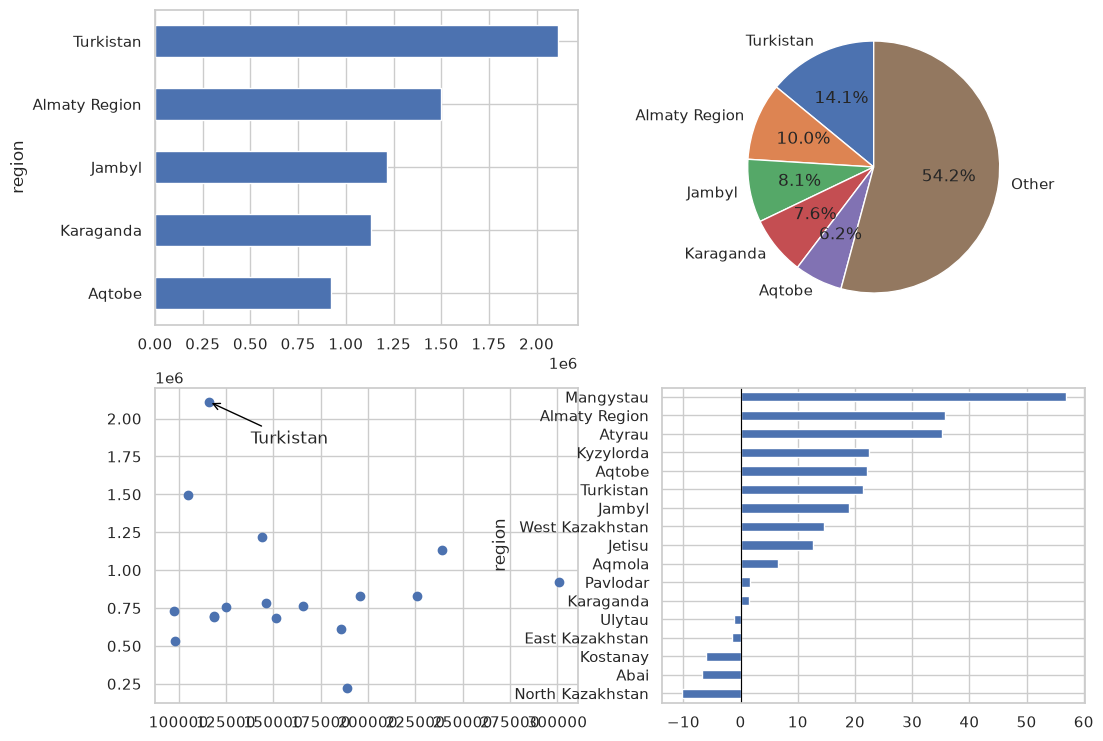

In [56]:
def _t54():
    ax = dax[1, 1]
    bars = [p.get_width() for p in ax.patches]
    return (len(bars) == 17 and np.allclose(bars, sorted(regions["growth_pct"])) and bars[0] < 0
            and sorted(t.get_text() for t in ax.get_yticklabels()) == sorted(regions["region"]))
check("5.4", _t54)
dash

### Task 5.5 (3 pts): Titles and axis names

Give **every one of the four axes** its own (different) title. The three non-pie panels also need an x label and a y label
(the pie does not need axis names).

*Hint:* `ax.set(title=..., xlabel=..., ylabel=...)`. For example the growth panel: x label `"Growth 2009 to 2022, %"`.

In [57]:
# ax.set(...) sets several properties at once: title, xlabel, ylabel.
dax[0, 0].set(title="Top 5 regions by population (2022)",
              xlabel="Population 2022", ylabel="Region")

# The pie has no axes in the usual sense, so only a title.
# pandas writes the Series name as a y label on pies; ylabel="" removes it.
dax[0, 1].set(title="Population share: top 5 vs other regions", ylabel="")

dax[1, 0].set(title="Area vs population",
              xlabel="Area, km2", ylabel="Population 2022")

dax[1, 1].set(title="Population growth by region",
              xlabel="Growth 2009 to 2022, %", ylabel="Region")

[Text(0.5, 1.0, 'Population growth by region'),
 Text(0.5, 4.44444444444443, 'Growth 2009 to 2022, %'),
 Text(508.85475852272714, 0.5, 'Region')]

Task 5.5: PASS


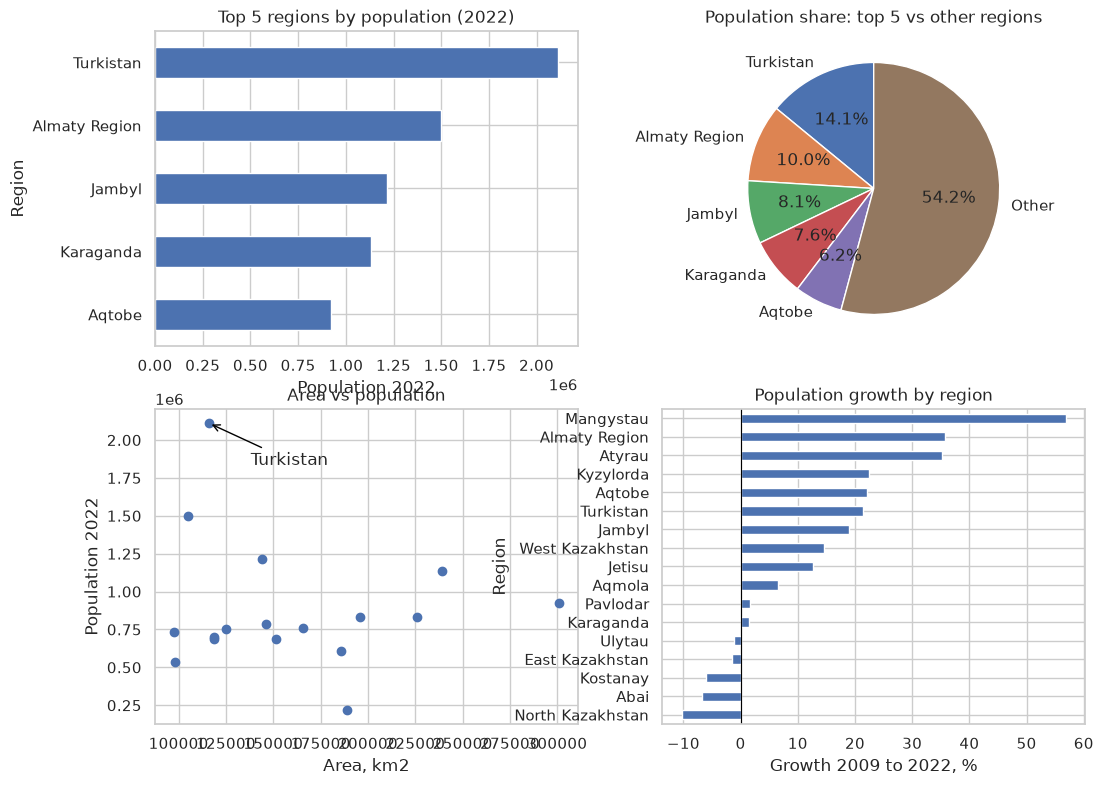

In [58]:
def _t55():
    titles = [a.get_title() for a in dax.ravel()]
    others = [dax[0, 0], dax[1, 0], dax[1, 1]]
    return (all(titles) and len(set(titles)) == 4 and all(a.get_xlabel() for a in others) and all(a.get_ylabel() for a in others))
check("5.5", _t55)
dash

### Task 5.6 (3 pts): Figure title and saving

1. Give the whole figure the title `"Kazakhstan regions dashboard"` with `dash.suptitle(...)`.
2. Call `dash.tight_layout()` so that the panels do not overlap.
3. Save `dash` to `kz_dashboard.png` with `dpi=150`.

In [59]:
# suptitle = "super title": one title for the WHOLE figure (above all panels).
dash.suptitle("Kazakhstan regions dashboard", fontsize=16)

# tight_layout recalculates the spacing so titles, labels and panels do not overlap.
dash.tight_layout()

# Save to a PNG. 12 inches * 150 dpi = 1800 pixels wide.
dash.savefig("kz_dashboard.png", dpi=150)

Task 5.6: PASS


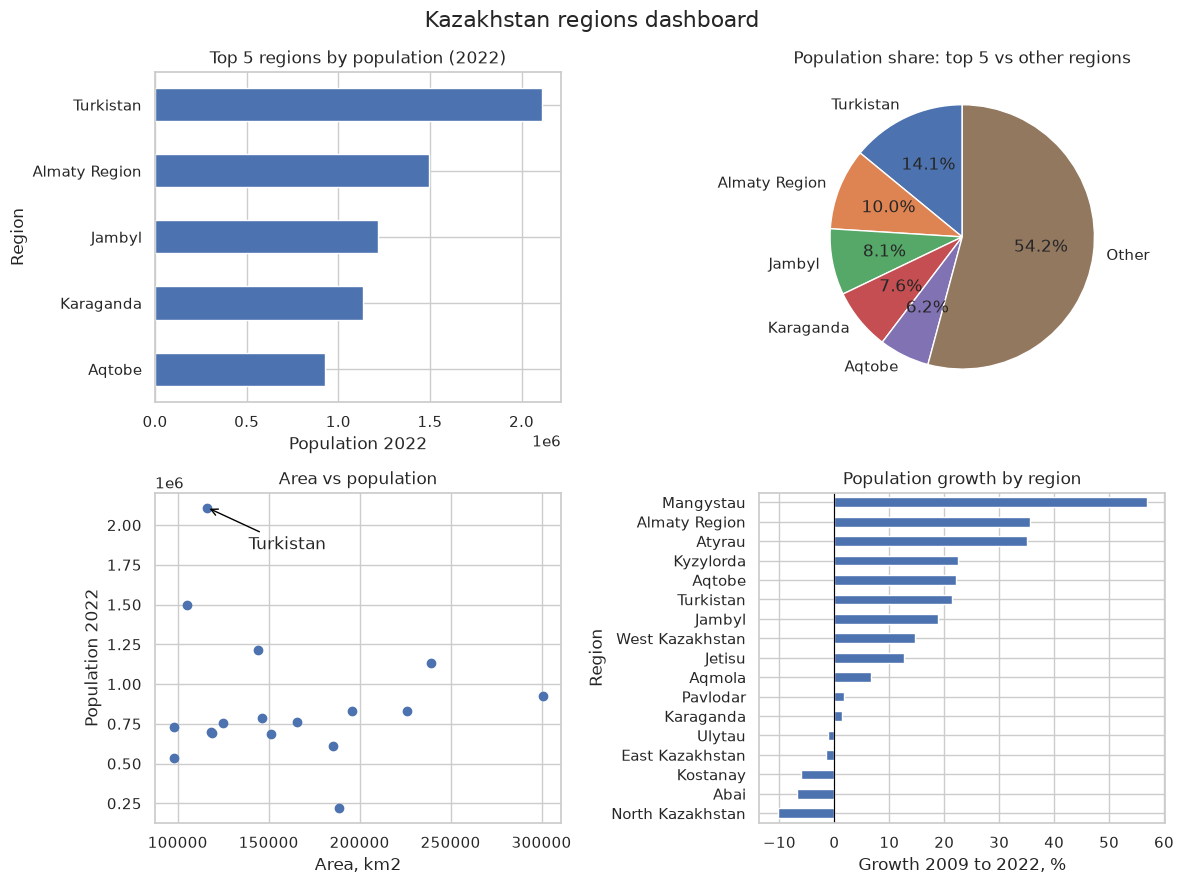

In [60]:
def _suptitle(f):   # get_suptitle() exists only in matplotlib 3.8+, the private attribute works everywhere
    st = getattr(f, "_suptitle", None)
    return st.get_text() if st is not None else ""

check("5.6", lambda: _suptitle(dash) == "Kazakhstan regions dashboard" and os.path.exists("kz_dashboard.png")
      and _png_width("kz_dashboard.png")[0] and _png_width("kz_dashboard.png")[1] >= 1700)   # 12 inches * 150 dpi = 1800
dash

---
# Final score
Run the next cell.

In [61]:
summary()

,max,earned,result
task,,,
1.1,4,4,PASS
1.2,5,5,PASS
1.3,5,5,PASS
1.4,4,4,PASS
1.5,4,4,PASS
2.1,5,5,PASS
2.2,5,5,PASS
2.3,5,5,PASS
2.4,5,5,PASS



Part 1:  22 / 22
Part 2:  20 / 20
Part 3:  24 / 24
Part 4:  15 / 15
Part 5:  19 / 19
TOTAL (automatic): 100 / 100


---
# Defense questions

1. What is a `Figure` and what is an `Axes`? What is the difference between `plt.plot(...)` and `ax.plot(...)`?
2. What does the format string `"ko--"` mean? How would you write the same with keyword arguments?
3. What does `sharex=True` do? What do `wspace` and `hspace` control?
4. Why must you call `set_xticks` before `set_xticklabels`?
5. Why did we remove the row with `tip_pct` at least 1 before plotting? What would the histogram look like without that step?
6. What is the difference between a grouped and a stacked bar chart? Why did we divide each row of the crosstab by its total in task 3.5?
7. **Live demo:** in task 3.6 plot `tips` instead of `clean`. What happens to the histogram and why?
8. In Part 5, why did we group the small regions into `Other` before drawing the pie? When is a bar chart better than a pie?
9. In the heatmap (task 4.4): why are all diagonal values equal to 1? Does a high correlation mean that one variable causes the other?

### Answers to the defense questions

1. **Figure vs Axes.** A `Figure` is the whole window/canvas. An `Axes` is one plot area inside it, with its own x and y axis, title and legend. A figure can hold many axes.
   `plt.plot(...)` draws on the *current* axes that pyplot remembers in the background. `ax.plot(...)` draws on exactly the axes you name. In Jupyter the figure closes after the cell, so a later `plt.title(...)` would land on a new empty figure, while `ax.set_title(...)` always reaches the right plot.
2. **`"ko--"`** means black colour (`k`), circle markers (`o`) and a dashed line (`--`). With keyword arguments: `ax.plot(walk, color="black", marker="o", linestyle="--")`.
3. **`sharex=True`** makes all panels use one common x axis: the same range and the same zoom. `wspace` is the horizontal gap between columns and `hspace` is the vertical gap between rows (as a share of the average panel width or height).
4. **`set_xticks` before `set_xticklabels`:** the labels are only texts glued to existing tick positions. `set_xticks` first decides where the 12 ticks are, then `set_xticklabels` writes one text at each. In the other order the labels would attach to matplotlib's automatic ticks (for example 0, 2, 4, ...) and come out wrong or shifted.
5. **The 240% tip** is a data entry error. Without removing it, the histogram's x axis would stretch to 2.4, all real values (about 0.05 to 0.3) would squeeze into a few bars on the left, and one lonely bar would sit far to the right. The mean and correlations would also be distorted.
6. **Grouped vs stacked bars.** Grouped bars stand side by side, which is good for comparing the values themselves. Stacked bars sit on top of each other inside one bar, which is good for showing how a total is split into parts. We divided each crosstab row by its total because days have different numbers of bills. Shares (each row = 1) make the days comparable; raw counts would mostly show which day was busier.
7. **Plotting `tips` instead of `clean`:** the outlier at 2.4 comes back. The 30 bins now cover 0 to 2.4, so each bin is very wide, almost all bills fall into the first 2–3 bars, and the shape of the distribution disappears. The density curve gets a long flat tail to the right.
8. **"Other" in the pie:** 17 slices would include many thin slices with unreadable labels and percentages. Keeping the top 5 plus one "Other" slice keeps the pie readable. A bar chart is better when there are many categories, when you need to compare similar values precisely (people judge lengths better than angles), or when the values are not parts of one whole (like the growth percentages, which can even be negative).
9. **Heatmap diagonal = 1:** every variable is perfectly correlated with itself. High correlation does **not** prove causation: it only shows that two variables move together. A third factor may drive both, or the link may be a coincidence. For example `tip` and `total_bill` are correlated because the tip is calculated from the bill, not the other way round.